#1.Mount Google Drive
This step mounts Google Drive to access datasets and files stored in Drive. Paths are defined for the folder containing the images and the captions file.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
IMAGES_PATH = '/content/drive/MyDrive/Flickr8k_Dataset/Images'
CAPTIONS_PATH = '/content/drive/MyDrive/Flickr8k_Dataset/captions.txt'

Mounted at /content/drive


#2.Import Required Libraries
This step imports the necessary Python libraries for tasks such as image processing, data preprocessing, model building, training, and evaluation.





In [ ]:
import os
import numpy as np
import pickle
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Embedding, LSTM, Dropout, add
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt
import nltk
from nltk.translate.bleu_score import sentence_bleu
import gc



#3.Load and Preprocess Captions
This step reads the captions file, processes each caption by adding special tokens (startseq and endseq), and organizes captions by their associated image IDs.



In [ ]:
def load_captions(filepath):
    captions = {}
    with open(filepath, 'r') as file:
        next(file)  # Skip header
        for line in file:
            image_id, caption = line.strip().split(',', 1)
            image_id = image_id.split('.')[0]
            captions.setdefault(image_id, []).append('startseq ' + caption + ' endseq')
    return captions

captions_dict = load_captions(CAPTIONS_PATH)
print(f"Loaded captions for {len(captions_dict)} images.")


Loaded captions for 8091 images.


#4.Extract Image Features
This step uses the VGG16 model, pre-trained on ImageNet, to extract deep feature representations for each image in the dataset. These features will serve as input for the caption generation model.



In [ ]:

# Paths for images and saving features
IMAGES_PATH = '/content/drive/MyDrive/Flickr8k_Dataset/Images'  # Folder containing images
FEATURES_FOLDER_PATH = '/content/drive/MyDrive/Flickr8k_Dataset/feature_files'  # Folder to save features
FEATURE_FILE_PATH = f'{FEATURES_FOLDER_PATH}/image_features.pkl'  # File path for features

# Function to extract image features
def extract_features(images_path):
    """
    Extracts features for all images in the given folder using the VGG16 model.

    Args:
        images_path (str): Path to the folder containing images.

    Returns:
        dict: A dictionary mapping image IDs to their feature vectors.
    """
    print("Loading VGG16 model...")
    model = VGG16(weights='imagenet')  # Load pre-trained VGG16 model
    model = Model(inputs=model.input, outputs=model.layers[-2].output)  # Remove the final classification layer
    features = {}  # Dictionary to store image features

    # Iterate over all images in the folder
    for img_name in os.listdir(images_path):
        img_path = os.path.join(images_path, img_name)  # Full path to the image
        image_id = img_name.split('.')[0]  # Extract image ID
        try:
            # Load and preprocess the image
            img = load_img(img_path, target_size=(224, 224))  # Resize to VGG16 input size
            img = img_to_array(img)  # Convert to numpy array
            img = np.expand_dims(img, axis=0)  # Add batch dimension
            img = preprocess_input(img)  # Preprocess for VGG16

            # Extract features using VGG16
            features[image_id] = model.predict(img, verbose=0)[0]
        except Exception as e:
            print(f"Error processing {img_name}: {e}")
    return features

# Ensure the features directory exists
if not os.path.exists(FEATURES_FOLDER_PATH):
    print(f"Creating features directory at {FEATURES_FOLDER_PATH}")
    os.makedirs(FEATURES_FOLDER_PATH)

# Extract and save features if not already saved
if not os.path.exists(FEATURE_FILE_PATH):
    print("Extracting image features...")
    image_features = extract_features(IMAGES_PATH)  # Extract features from images
    with open(FEATURE_FILE_PATH, 'wb') as file:
        pickle.dump(image_features, file)  # Save the features to a .pkl file
    print(f"Features extracted and saved to: {FEATURE_FILE_PATH}")
else:
    print("Loading existing image features...")
    with open(FEATURE_FILE_PATH, 'rb') as file:
        image_features = pickle.load(file)  # Load existing features
    print(f"Loaded features for {len(image_features)} images.")


Loading existing image features...
Loaded features for 3714 images.


#5.Tokenizing Captions
This step tokenizes all the captions to build a vocabulary and calculates the maximum length of captions. This tokenizer will be used for converting text captions into sequences of integers.



In [ ]:
all_captions = [caption for captions in captions_dict.values() for caption in captions]
tokenizer = Tokenizer()
tokenizer.fit_on_texts(all_captions)

vocab_size = len(tokenizer.word_index) + 1
max_length = max(len(caption.split()) for caption in all_captions)
print(f"Vocabulary size: {vocab_size}, Max caption length: {max_length}")


Vocabulary size: 8496, Max caption length: 40


#6.Save Data in Batches
This step generates input-output pairs for training by combining image features and corresponding captions. The data is saved in smaller batches as .npz files to optimize memory usage during training.






In [ ]:
def save_data_in_batches(captions_dict, image_features, tokenizer, max_length, batch_size, file_prefix):
    captions_keys = list(captions_dict.keys())
    for i in range(0, len(captions_keys), batch_size):
        batch_keys = captions_keys[i:i + batch_size]
        X1, X2, y = [], [], []
        for img_id in batch_keys:
            if img_id not in image_features:
                continue
            for caption in captions_dict[img_id]:
                seq = tokenizer.texts_to_sequences([caption])[0]
                for j in range(1, len(seq)):
                    in_seq, out_seq = seq[:j], seq[j]
                    in_seq = pad_sequences([in_seq], maxlen=max_length, padding='post')[0]
                    out_seq = to_categorical([out_seq], num_classes=vocab_size)[0]
                    X1.append(image_features[img_id])
                    X2.append(in_seq)
                    y.append(out_seq)
        np.savez(f"{file_prefix}_batch_{i // batch_size}.npz", X1=np.array(X1), X2=np.array(X2), y=np.array(y))
        print(f"Saved batch {i // batch_size} with {len(X1)} samples.")

save_data_in_batches(captions_dict, image_features, tokenizer, max_length, batch_size=100, file_prefix="training_data")


Saved batch 0 with 5995 samples.
Saved batch 1 with 6002 samples.
Saved batch 2 with 6227 samples.
Saved batch 3 with 6058 samples.
Saved batch 4 with 5960 samples.
Saved batch 5 with 5911 samples.
Saved batch 6 with 5810 samples.
Saved batch 7 with 6119 samples.
Saved batch 8 with 5931 samples.
Saved batch 9 with 6167 samples.
Saved batch 10 with 5849 samples.
Saved batch 11 with 5991 samples.
Saved batch 12 with 6037 samples.
Saved batch 13 with 5842 samples.
Saved batch 14 with 5683 samples.
Saved batch 15 with 5812 samples.
Saved batch 16 with 6012 samples.
Saved batch 17 with 6009 samples.
Saved batch 18 with 5953 samples.
Saved batch 19 with 6040 samples.
Saved batch 20 with 5813 samples.
Saved batch 21 with 5991 samples.
Saved batch 22 with 5789 samples.
Saved batch 23 with 5853 samples.
Saved batch 24 with 5843 samples.
Saved batch 25 with 6048 samples.
Saved batch 26 with 6033 samples.
Saved batch 27 with 5941 samples.
Saved batch 28 with 5911 samples.
Saved batch 29 with 5906

#7.Define the Model
This step defines the architecture of the image captioning model, combining the encoder (image features) and decoder (captions). The decoder uses an embedding layer and LSTM to generate word predictions.

In [ ]:
inputs1 = Input(shape=(4096,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)
model.compile(loss='categorical_crossentropy', optimizer='adam')
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3             │ (None, 40)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ input_layer_2             │ (None, 4096)           │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding_1 (Embedding)   │ (None, 40, 256)        │      2,174,976 │ input_layer_3[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_2 (Dropout)       │ (None, 4096)           │              0 │ input_layer_2[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_3 (Dropout)       │ (None, 40, 256)        │              0 │ embedding_1[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ not_equal_1 (NotEqual)    │ (None, 40)             │              0 │ input_layer_3[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_3 (Dense)           │ (None, 256)            │      1,048,832 │ dropout_2[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_1 (LSTM)             │ (None, 256)            │        525,312 │ dropout_3[0][0],       │
│                           │                        │                │ not_equal_1[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_1 (Add)               │ (None, 256)            │              0 │ dense_3[0][0],         │
│                           │                        │                │ lstm_1[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_4 (Dense)           │ (None, 256)            │         65,792 │ add_1[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_5 (Dense)           │ (None, 8496)           │      2,183,472 │ dense_4[0][0]          │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 5,998,384 (22.88 MB)

 Trainable params: 5,998,384 (22.88 MB)

 Non-trainable params: 0 (0.00 B)

#8.Train the Model
This step loads the preprocessed batches of data and trains the model using the encoder-decoder framework. The training process optimizes the model's weights to minimize the loss function, enabling it to generate accurate captions.

In [ ]:
# Data Generator for Model Training
def data_generator(file_prefix, batch_size, max_length, vocab_size):
    def generator():
        i = 0
        while True:
            file_name = f"{file_prefix}_batch_{i}.npz"
            if not os.path.exists(file_name):
                break
            data = np.load(file_name)
            if len(data['X1']) == 0 or len(data['X2']) == 0 or len(data['y']) == 0:
                i += 1
                continue
            yield ((data['X1'], data['X2']), data['y'])
            i += 1

    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            (
                tf.TensorSpec(shape=(None, 4096), dtype=tf.float32),
                tf.TensorSpec(shape=(None, max_length), dtype=tf.int32),
            ),
            tf.TensorSpec(shape=(None, vocab_size), dtype=tf.float32),
        )
    )
    return dataset

# Create Dataset and Train Model
dataset = data_generator("training_data", batch_size=32, max_length=max_length, vocab_size=vocab_size)
steps_per_epoch = len([f for f in os.listdir('.') if f.startswith("training_data_batch")])

checkpoint = ModelCheckpoint('model_epoch_{epoch:02d}.keras', save_best_only=False)

# Train the model
print("Starting model training...")
model.fit(
    dataset,
    steps_per_epoch=steps_per_epoch,
    epochs=10,
    callbacks=[checkpoint]
)

print("Training completed.")

Starting model training...
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - loss: 6.1459
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - loss: 4.9695
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - loss: 4.3366
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - loss: 3.8155
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - loss: 3.4836
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - loss: 3.2774
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - loss: 3.1158
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - loss: 2.9868
Epoch 9/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - loss: 2.8672
Epoch 10/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - loss: 2.7603
Training completed.


#9.Greedy Decoding Function
This step implements a greedy decoding method to generate captions for unseen images. The next word in the caption is predicted by selecting the most probable word at each step.



In [ ]:
def greedy_predictions(image_feature, model, tokenizer, max_length):
    caption = "startseq"
    for _ in range(max_length):
        seq = tokenizer.texts_to_sequences([caption])[0]
        seq = pad_sequences([seq], maxlen=max_length, padding='post')
        y_pred = model.predict([np.expand_dims(image_feature, axis=0), seq], verbose=0)
        next_word = tokenizer.index_word.get(np.argmax(y_pred), "")
        if next_word == "endseq":
            break
        caption += " " + next_word
    return caption.replace("startseq", "").replace("endseq", "").strip()


#10.Evaluate BLEU Score
This step evaluates the quality of the generated captions using the BLEU (Bilingual Evaluation Understudy) score. BLEU compares the generated captions with ground-truth captions to assess their similarity.

In [ ]:

from nltk.translate.bleu_score import corpus_bleu
from nltk.tokenize import word_tokenize

def preprocess_caption(caption):
    """
    Preprocess caption by removing special tokens and converting to lowercase
    """
    return caption.replace('startseq', '').replace('endseq', '').strip().lower().split()

def calculate_bleu_scores(image_features, captions_dict, model, tokenizer, max_length, max_samples=None):
    """
    Calculate BLEU scores for generated captions

    Args:
        image_features (dict): Dictionary of image features
        captions_dict (dict): Dictionary of reference captions
        model: The trained model
        tokenizer: The tokenizer used for captions
        max_length (int): Maximum length of captions
        max_samples (int, optional): Maximum number of samples to evaluate

    Returns:
        dict: Dictionary containing BLEU scores
    """
    references = []
    hypotheses = []

    # Get common image IDs between features and captions
    image_ids = list(set(image_features.keys()) & set(captions_dict.keys()))

    # Limit samples if specified
    if max_samples and max_samples < len(image_ids):
        image_ids = image_ids[:max_samples]

    print(f"Evaluating BLEU scores for {len(image_ids)} images...")

    for img_id in image_ids:
        # Generate caption for the image
        features = image_features[img_id]
        generated_caption = greedy_predictions(features, model, tokenizer, max_length)

        # Process generated caption
        hypothesis = preprocess_caption(generated_caption)

        # Process reference captions
        reference = [preprocess_caption(cap) for cap in captions_dict[img_id]]

        references.append(reference)
        hypotheses.append(hypothesis)

    # Calculate BLEU scores for different n-grams
    bleu_scores = {}
    weights = [
        (1.0, 0, 0, 0),    # BLEU-1
        (0.5, 0.5, 0, 0),  # BLEU-2
        (0.33, 0.33, 0.33, 0),  # BLEU-3
        (0.25, 0.25, 0.25, 0.25)  # BLEU-4
    ]

    for i, weight in enumerate(weights, 1):
        score = corpus_bleu(references, hypotheses, weights=weight)
        bleu_scores[f'bleu-{i}'] = score
        print(f'BLEU-{i} score: {score:.4f}')

    return bleu_scores

def evaluate_model(image_features, captions_dict, model, tokenizer, max_length, sample_size=100):
    """
    Evaluate the model using BLEU scores
    """
    print("Starting model evaluation...")
    try:
        scores = calculate_bleu_scores(
            image_features,
            captions_dict,
            model,
            tokenizer,
            max_length,
            max_samples=sample_size
        )

        # Print results
        print("\nEvaluation Results:")
        print("-" * 30)
        for metric, score in scores.items():
            print(f"{metric.upper()}: {score:.4f}")

        return scores

    except Exception as e:
        print(f"Error during evaluation: {e}")
        return None

# Example usage:
scores = evaluate_model(image_features, captions_dict, model, tokenizer, max_length, sample_size=5)

Starting model evaluation...
Evaluating BLEU scores for 5 images...
BLEU-1 score: 0.7391
BLEU-2 score: 0.6005
BLEU-3 score: 0.4160
BLEU-4 score: 0.2181

Evaluation Results:
------------------------------
BLEU-1: 0.7391
BLEU-2: 0.6005
BLEU-3: 0.4160
BLEU-4: 0.2181


#11.Display Image with Caption
This step displays images with their generated captions. It visually validates the model's performance by comparing generated captions to the image content.

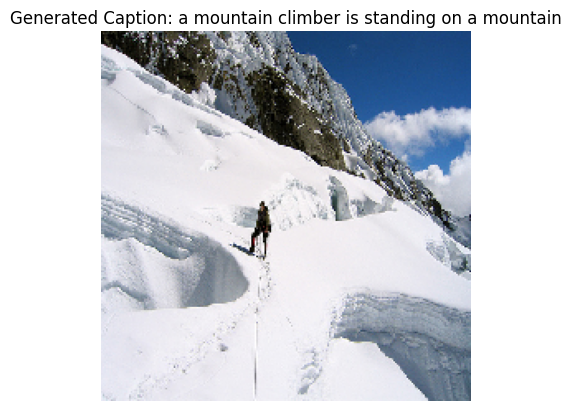

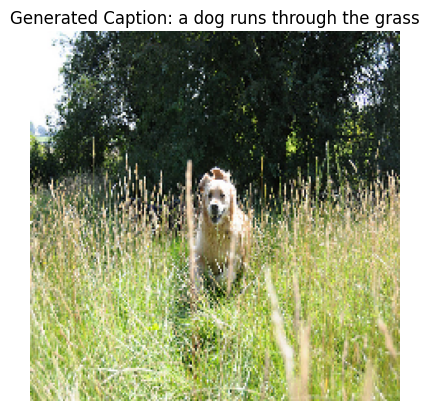

In [ ]:
def display_images_with_captions(image_features, tokenizer, max_length, images_path, model, num_images=1, skip_images=1):

    count = 0
    skip_count = 0

    for img_id, feature in image_features.items():
        if skip_count < skip_images:  # Skip the first few images
            skip_count += 1
            continue

        if count >= num_images:  # Limit the number of images displayed
            break

        try:
            # Generate caption
            caption =  greedy_predictions(feature, model, tokenizer, max_length)

            # Construct image path
            img_path = os.path.join(images_path, f"{img_id}.jpg")

            if os.path.exists(img_path):
                img = load_img(img_path, target_size=(224, 224))
                plt.imshow(img)
                plt.axis('off')
                plt.title(f"Generated Caption: {caption}")
                plt.show()
                count += 1  # Increment count for displayed images
            else:
                print(f"Image not found: {img_path}")
        except Exception as e:
            print(f"Error displaying image {img_id}: {e}")

# Call the function to display the image with caption
display_images_with_captions(image_features, tokenizer, max_length, IMAGES_PATH, model, num_images=2, skip_images=1)
